# Q3: Stitching pairs of images 
    
The first step is to write code to stitch together a single pair of images. For this part, you will be working with uttower_left.JPG and uttower_right.JPG pair

Steps:
- Compute SIFT key-points and descriptors for both images.
- Calculate distances between descriptors in the first image and those in the second to build a similarity matrix.
- From this matrix, select candidate matches. You may either keep all pairs below a distance threshold or choose the top few hundred pairs with the smallest distances.
- Run RANSAC to estimate a homography mapping one image onto the other. Report the number of inliers and the average residual for the inliers (squared distance between the point coordinates in one image and the transformed coordinates of the matching point in the other image). Also, display the locations of inlier matches in both images. For RANSAC, a very simple implementation is sufficient. Use four matches to initialize the homography in each iteration. You should
output a single transformation that gets the most inliers in the course of all the iterations. For the various RANSAC parameters (number of iterations, inlier threshold), play around with a few "reasonable" values and pick the ones that work best.
- Warp one image onto the other using the estimated transformation.
- Create a canvas large enough to hold both warped images. Blend them into a panorama by averaging pixel values in the overlapping region

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [2]:
img_left = cv.imread('uttower_left.JPG', cv.IMREAD_GRAYSCALE)
img_right = cv.imread('uttower_right.JPG', cv.IMREAD_GRAYSCALE)

### Finding the SIFT descriptors anmd keypoints


In [10]:
sift = cv.SIFT_create()

kp_left, des_left = sift.detectAndCompute(img_left, None)
kp_right, des_right = sift.detectAndCompute(img_right, None)

print(f"{len(kp_left)} keypoints in the left image.")
print(f"{len(kp_right)} keypoints in the right image.")

5317 keypoints in the left image.
4195 keypoints in the right image.


### Using the brute force matcher to match them

In [17]:
bf = cv.BFMatcher()

matches = bf.knnMatch(des_left, des_right, 2)

print(f"shape of matches: {np.shape(matches)}")
print(f"found {len(matches)} matches")

shape of matches: (5317, 2)
found 5317 matches


In [22]:
# working cell- ignore

print(matches[0])

fmatch =matches[0]

print(fmatch[0].distance)

(< cv2.DMatch 000002000838D8D0>, < cv2.DMatch 000002000838D850>)
276.9512634277344


### Using lowes ratio test to keep only the good ones

In [29]:
good_matches = []
for m, n in matches:
    if m.distance < 0.75 * n.distance:
        good_matches.append(m)

print(f"left with {len(good_matches)} matches")

left with 1094 matches


In [30]:
src_pts = np.float32([ kp_left[m.queryIdx].pt for m in good_matches ]).reshape(-1,1,2)
dst_pts = np.float32([ kp_right[m.trainIdx].pt for m in good_matches ]).reshape(-1,1,2)
#getx,y for each match

In [31]:
M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

print(M)

[[ 1.29718472e+00 -7.45167524e-02 -5.73141850e+02]
 [ 1.68980758e-01  1.21863224e+00 -1.67514131e+02]
 [ 2.78689905e-04  2.03562882e-05  1.00000000e+00]]


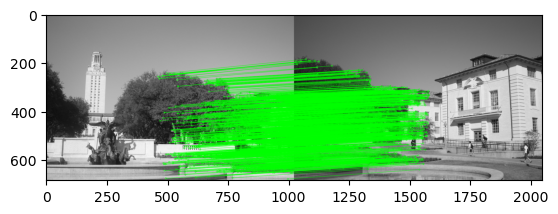

In [32]:
# We need at least 4 good matches to find the homography
MIN_MATCH_COUNT = 4

if len(good_matches) > MIN_MATCH_COUNT:
    # Get the coordinates of the good matches
    src_pts = np.float32([ kp_left[m.queryIdx].pt for m in good_matches ]).reshape(-1, 1, 2)
    dst_pts = np.float32([ kp_right[m.trainIdx].pt for m in good_matches ]).reshape(-1, 1, 2)

    # Compute the homography matrix 'M' using RANSAC
    M, mask = cv.findHomography(src_pts, dst_pts, cv.RANSAC, 5.0)

    # Get a mask to draw only the inlier matches
    matchesMask = mask.ravel().tolist()

else:
    print(f"Not enough matches are found - {len(good_matches)}/{MIN_MATCH_COUNT}")
    matchesMask = None


# Setup parameters for drawing the matches
draw_params = dict(matchColor = (0, 255, 0),  # draw matches in green
                   singlePointColor = None,
                   matchesMask = matchesMask,  # draw only inliers
                   flags = 2)

# Draw the matches and display the result
img_matches = cv.drawMatches(img_left, kp_left, img_right, kp_right, good_matches, None, **draw_params)

# In a script, you'd use this to show the image
# cv.imshow("Inlier Matches", img_matches)
# cv.waitKey(0)

# If you're in a Jupyter/Colab notebook, this is a better way to display it
from matplotlib import pyplot as plt
plt.imshow(img_matches, 'gray')
plt.show()